# Bài tập 1 - LeNet trên MNIST và phân tích biến thể

Họ và tên: Nguyễn Đăng Thới Toàn  
MSHV: 25C15062

## Mục tiêu

Bài tập triển khai LeNet trên MNIST và thực hiện Ablation Study để khảo sát ảnh hưởng của activation function, pooling và tầng convolution thứ hai đến accuracy, model size và training time.

Các thí nghiệm mở rộng bao gồm Robustness Testing dưới image corruptions, Cross-Dataset Evaluation trên EMNIST Digits, Error Analysis và Adversarial Robustness với FGSM. Kết quả được trình bày dưới dạng bảng và biểu đồ; các nhận xét định lượng sẽ được hoàn thiện sau khi chạy notebook.

## Thiết kế thực nghiệm

| Thành phần | Thiết lập |
|---|---|
| Dataset | MNIST: 50.000 ảnh train, 10.000 validation, 10.000 test; train/validation split cố định |
| Training | Adam (learning rate 0.001), batch size 128, 10 epochs cho mọi cấu hình |
| Random seeds | 42, 0 và 2026; huấn luyện độc lập theo từng seed |
| Ablation Study | Baseline: Tanh + AvgPool; các biến thể: ReLU, MaxPool, bỏ Conv2 |
| Data Augmentation | Random rotation ±15° và Gaussian noise (σ = 0.15) trên tập train |
| Robustness Testing | Gaussian noise, rotation, Gaussian blur trên MNIST test |
| Cross-Dataset Evaluation | EMNIST Digits test, không fine-tune |
| Error Analysis | Confusion matrix, per-class accuracy, misclassified samples (minh họa seed 42) |
| Adversarial Robustness | FGSM white-box trên tập con cố định của MNIST test |
| Metrics | Accuracy, percentage-point difference, parameters, training time, inference latency |

Các mô hình dùng cùng train/validation split và training budget. Mean và standard deviation (SD) được tính trên ba seed. Tập test chỉ được sử dụng để đánh giá, không tham gia tối ưu tham số hoặc lựa chọn epoch.

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

In [2]:
SPLIT_SEED = 42
SEEDS = (42, 0, 2026)
BATCH_SIZE = 128
EPOCHS = 10
EARLY_EPOCH = 3  # Convergence Analysis
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SPLIT_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f"PyTorch {torch.__version__}; device: {DEVICE}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name())

PyTorch 2.7.0+cu128; device: cuda
NVIDIA GeForce RTX 5090


## 1. Dữ liệu và tiền xử lý

Ảnh MNIST có kích thước 28 × 28 và được pad thành 32 × 32 để phù hợp với kiến trúc LeNet. Chỉ mô hình trong thí nghiệm Data Augmentation sử dụng các phép biến đổi ngẫu nhiên ở tập train; validation và test dùng preprocessing cố định.

Train/validation split được tạo bằng `SPLIT_SEED = 42` và giữ nguyên trong tất cả thí nghiệm.

### 1.1. Image transforms


In [3]:
class AddGaussianNoise:
    def __init__(self, sigma: float = 0.15):
        self.sigma = sigma

    def __call__(self, image: torch.Tensor) -> torch.Tensor:
        noise = torch.randn_like(image) * self.sigma
        return (image + noise).clamp(0, 1)


plain_transform = transforms.Compose([
    transforms.Pad(2), transforms.ToTensor()
])

augmented_transform = transforms.Compose([
    transforms.Pad(2), transforms.RandomRotation(15),
    transforms.ToTensor(), AddGaussianNoise(0.15)
])

### 1.2. Train/validation split


In [4]:
train_plain = datasets.MNIST("data", train=True, download=True, transform=plain_transform)
train_augmented = datasets.MNIST("data", train=True, download=False, transform=augmented_transform)
test_data = datasets.MNIST("data", train=False, download=True, transform=plain_transform)

indices = np.random.default_rng(SPLIT_SEED).permutation(len(train_plain))
train_indices, val_indices = indices[:50_000].tolist(), indices[50_000:].tolist()

### 1.3. DataLoader


In [5]:
def make_loader(dataset, indices=None, shuffle=False, seed=None):
    selected = Subset(dataset, indices) if indices is not None else dataset
    if shuffle and seed is None:
        raise ValueError("Cần seed khi shuffle train")
    generator = torch.Generator().manual_seed(seed) if shuffle else None

    return DataLoader(
        selected, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator,
        num_workers=2, pin_memory=DEVICE.type == "cuda"
    )

val_loader = make_loader(train_plain, val_indices)
test_loader = make_loader(test_data)
print(f"Train: {len(train_indices):,}; validation: {len(val_indices):,}; test: {len(test_data):,}")

Train: 50,000; validation: 10,000; test: 10,000


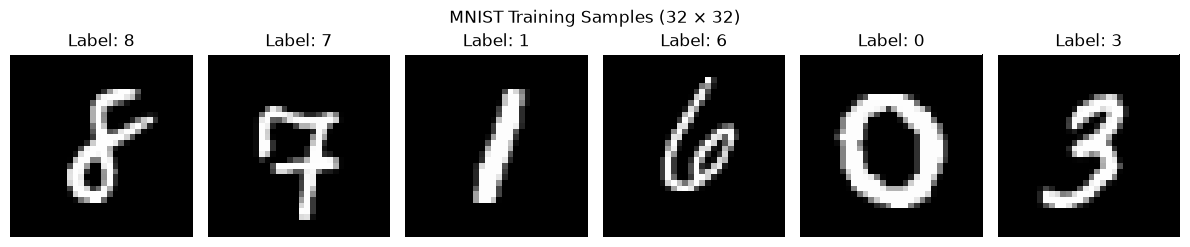

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, idx in zip(axes, train_indices[:6], strict=True):
    image, label = train_plain[idx]
    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set(title=f"Label: {label}")
    ax.axis("off")

plt.suptitle("MNIST Training Samples (32 × 32)")
plt.tight_layout()
plt.show()

## 2. Kiến trúc LeNet và training procedure

Baseline sử dụng Tanh và average pooling. Trong Ablation Study, mỗi biến thể thay đổi một lựa chọn kiến trúc, còn optimizer, batch size, dữ liệu và 10 training epochs được giữ nguyên.

Khi bỏ Conv2, kích thước đầu vào của classifier và số tham số cũng thay đổi. Do đó, kết quả biến thể này thể hiện ảnh hưởng của thay đổi kiến trúc tổng thể, không chỉ riêng tầng Conv2.

In [7]:
class LeNet(nn.Module):
    def __init__(self, activation="tanh", pooling="avg", skip_conv2=False):
        super().__init__()
        act = nn.Tanh if activation == "tanh" else nn.ReLU
        pool = nn.AvgPool2d if pooling == "avg" else nn.MaxPool2d

        layers = [nn.Conv2d(1, 6, 5), act(), pool(2)]
        if not skip_conv2:
            layers.extend([nn.Conv2d(6, 16, 5), act()])
        self.features = nn.Sequential(*layers, pool(2))

        with torch.no_grad():
            flat_features = self.features(torch.zeros(1, 1, 32, 32)).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(flat_features, 120), act(),
            nn.Linear(120, 84), act(), nn.Linear(84, 10)
        )

    def forward(self, image):
        return self.classifier(self.features(image))

Các cấu hình được xác định trước khi chạy thí nghiệm. Với cùng một seed, mô hình được khởi tạo lại và DataLoader dùng cùng seed để tạo thứ tự dữ liệu train. Điều này giúp việc so sánh giữa các cấu hình ít chịu ảnh hưởng của khác biệt ngẫu nhiên không cần thiết.


In [8]:
variants = {
    "baseline_tanh_avg": {"activation": "tanh", "pooling": "avg"},
    "relu_avg": {"activation": "relu", "pooling": "avg"},
    "tanh_max": {"activation": "tanh", "pooling": "max"},
    "tanh_avg_no_conv2": {"activation": "tanh", "pooling": "avg", "skip_conv2": True},
}

MODEL_LABELS = {
    "baseline_tanh_avg": "Baseline (Tanh + AvgPool)",
    "relu_avg": "ReLU + AvgPool",
    "tanh_max": "Tanh + MaxPool",
    "tanh_avg_no_conv2": "Tanh + AvgPool (no Conv2)",
    "augmented_tanh_avg": "Baseline + Augmentation",
}

for name, options in variants.items():
    model = LeNet(**options)
    print(f"{name}: {sum(p.numel() for p in model.parameters()):,} parameters")

baseline_tanh_avg: 61,706 parameters
relu_avg: 61,706 parameters
tanh_max: 61,706 parameters
tanh_avg_no_conv2: 46,570 parameters


In [9]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss = correct = total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, labels).item()
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return {"loss": total_loss / total, "accuracy": correct / total}

In [10]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    started = time.perf_counter()
    total_loss = correct = total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return total_loss / total, correct / total, elapsed

In [11]:
def train_model(model, train_loader, epochs=EPOCHS):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    history = []

    for epoch in range(1, epochs + 1):
        loss, accuracy, elapsed = train_one_epoch(model, train_loader, optimizer, criterion)
        validation = evaluate(model, val_loader)
        history.append({
            "epoch": epoch, "train_loss": loss, "train_accuracy": accuracy,
            "val_loss": validation["loss"], "val_accuracy": validation["accuracy"],
            "train_seconds": elapsed
        })

    return pd.DataFrame(history)

## 3. Ablation Study

Bốn cấu hình được huấn luyện từ đầu trong 10 epochs với mỗi seed (42, 0, 2026). Các bảng trình bày validation/test accuracy, parameter count và training time. Training time được đo trên toàn bộ vòng lặp train (bao gồm lấy batch và augmentation nếu có), không bao gồm validation.

Chênh lệch test accuracy so với baseline được tính trên từng cặp mô hình có cùng seed, sau đó tổng hợp mean ± SD. Cách so sánh này giúp quan sát sự ổn định của từng thay đổi kiến trúc.

In [12]:
models, histories, architecture_rows = {}, {}, []

for seed in SEEDS:
    for name, options in variants.items():
        set_seed(seed)
        model = LeNet(**options)
        loader = make_loader(train_plain, train_indices, shuffle=True, seed=seed)
        history = train_model(model, loader)
        test = evaluate(model, test_loader)

        models[(name, seed)] = model
        histories[(name, seed)] = history
        architecture_rows.append({
            "seed": seed, "model": name,
            "parameters": sum(p.numel() for p in model.parameters()),
            "val_accuracy_pct": 100 * history.iloc[-1]["val_accuracy"],
            "test_accuracy_pct": 100 * test["accuracy"],
            "train_seconds": history["train_seconds"].sum()
        })
        print(f"Hoàn thành {name}, seed={seed}")

architecture_runs = pd.DataFrame(architecture_rows)

Hoàn thành baseline_tanh_avg, seed=42
Hoàn thành relu_avg, seed=42
Hoàn thành tanh_max, seed=42
Hoàn thành tanh_avg_no_conv2, seed=42
Hoàn thành baseline_tanh_avg, seed=0
Hoàn thành relu_avg, seed=0
Hoàn thành tanh_max, seed=0
Hoàn thành tanh_avg_no_conv2, seed=0
Hoàn thành baseline_tanh_avg, seed=2026
Hoàn thành relu_avg, seed=2026
Hoàn thành tanh_max, seed=2026
Hoàn thành tanh_avg_no_conv2, seed=2026


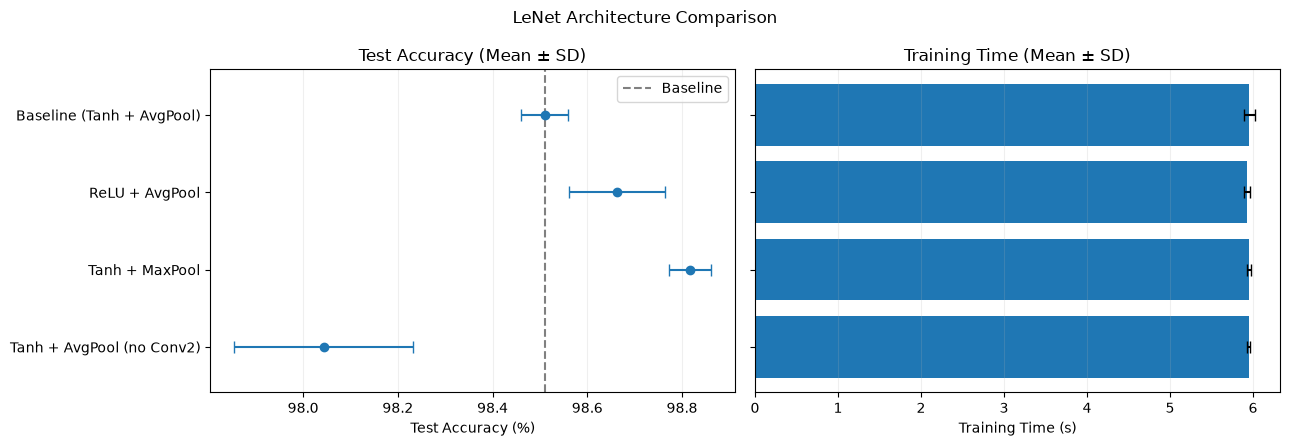

,Parameters
Architecture,
Baseline (Tanh + AvgPool),61706
ReLU + AvgPool,61706
Tanh + MaxPool,61706
Tanh + AvgPool (no Conv2),46570


In [13]:
architecture_summary = architecture_runs.groupby("model", sort=False).agg(
    parameters=("parameters", "first"),
    val_mean=("val_accuracy_pct", "mean"), val_sd=("val_accuracy_pct", "std"),
    test_mean=("test_accuracy_pct", "mean"), test_sd=("test_accuracy_pct", "std"),
    train_s_mean=("train_seconds", "mean"), train_s_sd=("train_seconds", "std"),
)

df = architecture_summary.loc[list(variants)]
labels = [MODEL_LABELS[name] for name in df.index]
y = np.arange(len(df))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].errorbar(df["test_mean"], y, xerr=df["test_sd"], fmt="o", capsize=4)
axes[0].axvline(df.loc["baseline_tanh_avg", "test_mean"], ls="--", color="gray", label="Baseline")
axes[1].barh(y, df["train_s_mean"], xerr=df["train_s_sd"], capsize=4)

for ax, title, xlabel in zip(
    axes,
    ["Test Accuracy (Mean ± SD)", "Training Time (Mean ± SD)"],
    ["Test Accuracy (%)", "Training Time (s)"],
):
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="x", alpha=0.2)

axes[0].set(yticks=y, yticklabels=labels)
axes[0].invert_yaxis()
axes[0].legend()
fig.suptitle("LeNet Architecture Comparison")
plt.tight_layout()
plt.show()

display(df[["parameters"]].set_axis(labels).rename_axis("Architecture").rename(columns={"parameters": "Parameters"}))

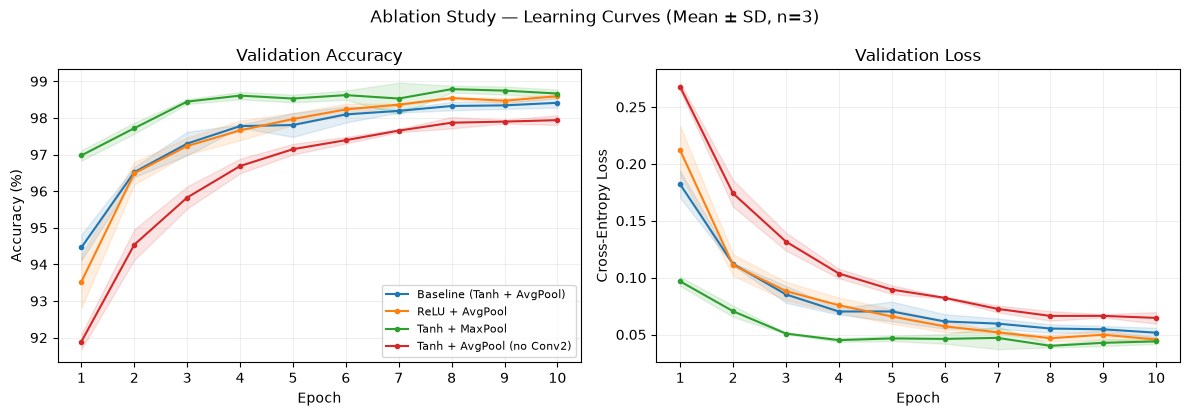

In [14]:
history_runs = pd.concat([
    frame.assign(model=name, seed=seed)
    for (name, seed), frame in histories.items()
], ignore_index=True)

metrics = [
    ("val_accuracy", "Validation Accuracy", "Accuracy (%)", 100),
    ("val_loss", "Validation Loss", "Cross-Entropy Loss", 1),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for ax, (metric, title, ylabel, scale) in zip(axes, metrics):
    for name in variants:
        stats = history_runs[history_runs["model"] == name].groupby("epoch")[metric].agg(["mean", "std"])
        x, y, sd = stats.index, stats["mean"] * scale, stats["std"] * scale
        line, = ax.plot(x, y, marker="o", ms=3, label=MODEL_LABELS[name])
        ax.fill_between(x, y - sd, y + sd, color=line.get_color(), alpha=0.12)

    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.grid(alpha=0.2)

axes[0].legend(fontsize=8)
fig.suptitle(f"Ablation Study — Learning Curves (Mean ± SD, n={len(SEEDS)})")
plt.tight_layout()
plt.show()

In [15]:
accuracy_by_seed = architecture_runs.pivot(
    index="seed", columns="model", values="test_accuracy_pct"
)

paired_rows = []
for name in ("relu_avg", "tanh_max", "tanh_avg_no_conv2"):
    delta = accuracy_by_seed[name] - accuracy_by_seed["baseline_tanh_avg"]
    paired_rows.append({
        "Architecture": MODEL_LABELS[name],
        "Δ Test Accuracy (%)": f"{delta.mean():+.3f} ± {delta.std(ddof=1):.3f}"
    })

paired_summary = pd.DataFrame(paired_rows)
display(paired_summary.style.hide(axis="index"))

Architecture,Δ Test Accuracy (%)
ReLU + AvgPool,+0.153 ± 0.065
Tanh + MaxPool,+0.307 ± 0.095
Tanh + AvgPool (no Conv2),-0.467 ± 0.153


### Nhận xét Ablation Study

TODO: Dựa vào `architecture_summary` và `paired_summary`, nhận xét ảnh hưởng của ReLU, MaxPool và bỏ Conv2 lên test accuracy. Trình bày cả độ lệch chuẩn giữa các seed, parameter count và training time; không mặc định biến thể tốt hơn chỉ vì accuracy trung bình cao hơn.

## 4. Convergence Analysis

Với 50.000 ảnh train và batch size 128, mỗi epoch có khoảng 391 mini-batches. Epoch 3 tương ứng khoảng 1.173 lần cập nhật tham số, còn epoch 10 khoảng 3.910 lần. Mô hình có thể đạt accuracy cao từ những epoch đầu, nhưng điều này không đồng nghĩa với việc quá trình huấn luyện đã hội tụ.

Phần dưới sử dụng training history của baseline với seed 42 trong thí nghiệm Ablation Study, thay vì huấn luyện thêm một mô hình riêng. Đường train/validation accuracy và loss được theo dõi xuyên suốt 10 epochs; epoch 3 được đánh dấu làm mốc đối chiếu với epoch 10. Đây là một lần chạy đại diện, không thay thế kết quả thống kê trên ba seed.

In [16]:
convergence_seed = 42
convergence_history = histories[("baseline_tanh_avg", convergence_seed)].copy()
assert len(convergence_history) == EPOCHS

columns = ["epoch", "train_loss", "val_loss", "train_accuracy", "val_accuracy"]
summary = convergence_history.loc[
    convergence_history["epoch"].isin((EARLY_EPOCH, EPOCHS)), columns
].copy()

summary[["train_accuracy", "val_accuracy"]] *= 100

display(summary.rename(columns={
    "epoch": "Epoch", "train_loss": "Train Loss", "val_loss": "Validation Loss",
    "train_accuracy": "Train Accuracy (%)", "val_accuracy": "Validation Accuracy (%)"
}).round(3).style.hide(axis="index"))

Epoch,Train Loss,Validation Loss,Train Accuracy (%),Validation Accuracy (%)
3,0.083000,0.077000,97.504000,97.670000
10,0.019000,0.053000,99.446000,98.370000


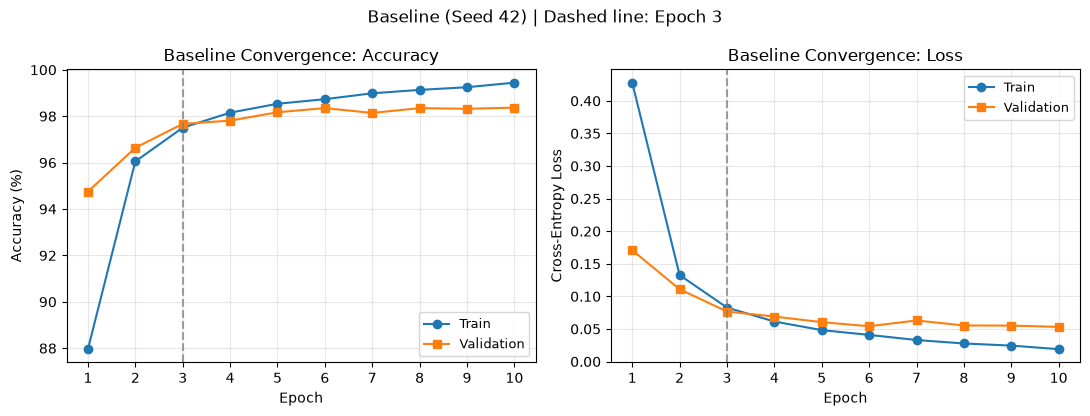

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
epochs = convergence_history["epoch"]

metrics = [
    ("accuracy", "Accuracy (%)", 100, "Baseline Convergence: Accuracy"),
    ("loss", "Cross-Entropy Loss", 1, "Baseline Convergence: Loss"),
]

for ax, (metric, ylabel, scale, title) in zip(axes, metrics):
    for stage, marker in [("train", "o"), ("val", "s")]:
        ax.plot(
            epochs, scale * convergence_history[f"{stage}_{metric}"],
            marker=marker, label="Train" if stage == "train" else "Validation"
        )

    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.axvline(EARLY_EPOCH, color="tab:gray", linestyle="--", alpha=0.75)
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle(f"Baseline (Seed {convergence_seed}) | Dashed line: Epoch {EARLY_EPOCH}")
plt.tight_layout()
plt.show()

### Nhận xét Convergence Analysis

TODO: Điền validation accuracy ở epoch 3: `[x]%`; epoch 10: `[y]%` (baseline, seed 42). Nhận xét quá trình giảm train/validation loss, mức cải thiện sau epoch 3 và sự chênh lệch giữa train và validation curves. Nếu chưa có dấu hiệu rõ ràng, không kết luận mô hình đã hội tụ hoàn toàn.

## 5. Robustness Testing

Thí nghiệm kiểm tra ảnh hưởng của Data Augmentation đến khả năng nhận dạng khi ảnh bị biến dạng. Mô hình augmented có cùng kiến trúc, optimizer, train/validation split và 10 training epochs như baseline. Điểm khác biệt là random rotation và Gaussian noise được áp dụng trên dữ liệu train.

Trước khi đánh giá ảnh bị corruption, cần đối chiếu accuracy trên MNIST test sạch để xác định đánh đổi giữa clean accuracy và robustness.

In [18]:
clean_accuracy = {
    (row.model, row.seed): row.test_accuracy_pct / 100
    for row in architecture_runs.itertuples(index=False)
}
augmentation_rows = []

for seed in SEEDS:
    set_seed(seed)
    model = LeNet(**variants["baseline_tanh_avg"])
    loader = make_loader(train_augmented, train_indices, shuffle=True, seed=seed)
    history = train_model(model, loader)
    test = evaluate(model, test_loader)

    models[("augmented_tanh_avg", seed)] = model
    histories[("augmented_tanh_avg", seed)] = history
    clean_accuracy[("augmented_tanh_avg", seed)] = test["accuracy"]

    augmentation_rows.append({
        "seed": seed,
        "val_accuracy_pct": 100 * history.iloc[-1]["val_accuracy"],
        "test_accuracy_pct": 100 * test["accuracy"],
        "train_seconds": history["train_seconds"].sum()
    })
    print(f"Hoàn thành augmentation, seed={seed}")

augmentation_runs = pd.DataFrame(augmentation_rows)

Hoàn thành augmentation, seed=42
Hoàn thành augmentation, seed=0
Hoàn thành augmentation, seed=2026


In [19]:
augmentation_summary = augmentation_runs.agg({
    "val_accuracy_pct": ["mean", "std"],
    "test_accuracy_pct": ["mean", "std"],
    "train_seconds": ["mean", "std"]
})

display(pd.DataFrame({
    "Metric": ["Validation Accuracy (%)", "Test Accuracy (%)", "Training Time (s)"],
    "Mean ± SD": [
        f"{row['mean']:.3f} ± {row['std']:.3f}"
        for _, row in augmentation_summary.T.iterrows()
    ]
}).style.hide(axis="index"))

Metric,Mean ± SD
Validation Accuracy (%),98.163 ± 0.236
Test Accuracy (%),98.290 ± 0.072
Training Time (s),10.816 ± 0.062


### Nhận xét Data Augmentation trên MNIST test sạch

TODO: So sánh clean test accuracy giữa baseline và augmented model (`[x ± SD]%` so với `[y ± SD]%`). Đây là đối chứng trước khi phân tích các ảnh bị corruption.

### 5.1. Image Corruption Evaluation

Các phép thử gồm Gaussian noise, rotation và Gaussian blur ở nhiều mức độ. Tất cả được áp dụng trên MNIST test và dùng cùng mức biến dạng cho baseline và augmented model. Gaussian noise sử dụng seed cố định để tạo các mẫu nhiễu nhất quán giữa các lần đánh giá.

Accuracy degradation được tính bằng clean accuracy trừ corrupted accuracy, theo đơn vị percentage points (pp). Giá trị âm nghĩa là corrupted accuracy cao hơn clean accuracy ở phép đo tương ứng.

In [20]:
def corrupt_batch(images, corruption, level, generator):
    if level == 0:
        return images
    if corruption == "noise":
        noise = torch.randn(images.shape, generator=generator) * level
        return (images + noise).clamp(0, 1)
    if corruption == "rotation":
        return torch.stack([
            TF.rotate(image, level, interpolation=InterpolationMode.BILINEAR)
            for image in images
        ])
    if corruption == "blur":
        return TF.gaussian_blur(images, kernel_size=5, sigma=float(level))
    raise ValueError(f"Corruption không hợp lệ: {corruption}")

In [21]:
@torch.inference_mode()
def accuracy_on_corruption(model, corruption, level):
    model.eval()
    generator = torch.Generator().manual_seed(2026)
    correct = total = 0

    for images, labels in test_loader:
        images = corrupt_batch(images, corruption, level, generator).to(DEVICE)
        predictions = model(images).argmax(1).cpu()
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return correct / total

corruption_levels = {
    "noise": [0, 0.1, 0.2, 0.3],
    "rotation": [0, 10, 20, 30],
    "blur": [0, 0.5, 1.0, 1.5],
}

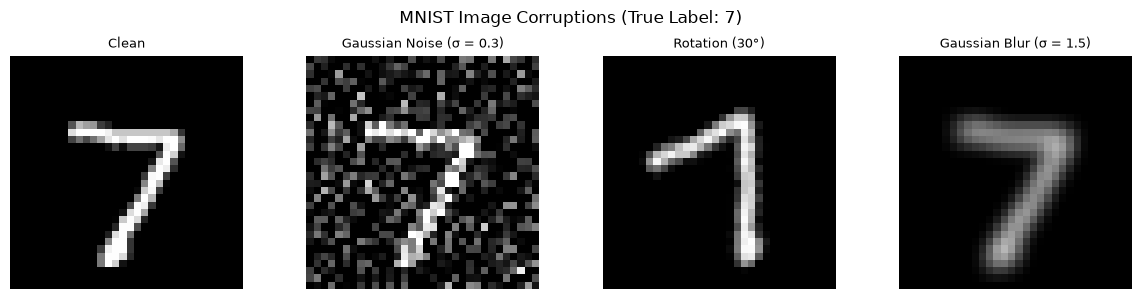

In [22]:
image, label = test_data[0]
examples = [
    ("Clean", image),
    ("Gaussian Noise (σ = 0.3)", corrupt_batch(image[None], "noise", 0.3, torch.Generator().manual_seed(2026))[0]),
    ("Rotation (30°)", corrupt_batch(image[None], "rotation", 30, torch.Generator())[0]),
    ("Gaussian Blur (σ = 1.5)", corrupt_batch(image[None], "blur", 1.5, torch.Generator())[0]),
]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (title, example) in zip(axes, examples, strict=True):
    ax.imshow(example.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

plt.suptitle(f"MNIST Image Corruptions (True Label: {label})")
plt.tight_layout()
plt.show()

In [23]:
robustness_rows = []

for seed in SEEDS:
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        model, clean = models[(name, seed)], clean_accuracy[(name, seed)]
        for corruption, levels in corruption_levels.items():
            for level in levels:
                accuracy = accuracy_on_corruption(model, corruption, level)
                robustness_rows.append({
                    "seed": seed, "model": name, "corruption": corruption,
                    "level": level, "accuracy_pct": 100 * accuracy,
                    "degradation_pp": 100 * (clean - accuracy)
                })

robustness_runs = pd.DataFrame(robustness_rows)

In [24]:
robustness_summary = robustness_runs.groupby(
    ["model", "corruption", "level"], sort=False
).agg(
    accuracy_mean=("accuracy_pct", "mean"), accuracy_sd=("accuracy_pct", "std"),
    degradation_mean=("degradation_pp", "mean"), degradation_sd=("degradation_pp", "std")
).reset_index()

table = robustness_summary[["model", "corruption", "level"]].copy()
table["Accuracy (%)"] = robustness_summary.apply(
    lambda r: f"{r.accuracy_mean:.2f} ± {r.accuracy_sd:.2f}", axis=1
)
table["Degradation (pp)"] = robustness_summary.apply(
    lambda r: f"{r.degradation_mean:.2f} ± {r.degradation_sd:.2f}", axis=1
)

table["model"] = table["model"].map(MODEL_LABELS)
display(table.rename(columns={
    "model": "Model", "corruption": "Corruption", "level": "Level"
}).style.hide(axis="index"))

Model,Corruption,Level,Accuracy (%),Degradation (pp)
Baseline (Tanh + AvgPool),noise,0.000000,98.51 ± 0.05,-0.00 ± 0.00
Baseline (Tanh + AvgPool),noise,0.100000,97.12 ± 0.69,1.39 ± 0.73
Baseline (Tanh + AvgPool),noise,0.200000,85.87 ± 3.30,12.64 ± 3.34
Baseline (Tanh + AvgPool),noise,0.300000,69.67 ± 1.15,28.84 ± 1.20
Baseline (Tanh + AvgPool),rotation,0.000000,98.51 ± 0.05,-0.00 ± 0.00
Baseline (Tanh + AvgPool),rotation,10.000000,97.53 ± 0.05,0.98 ± 0.03
Baseline (Tanh + AvgPool),rotation,20.000000,93.17 ± 0.37,5.34 ± 0.34
Baseline (Tanh + AvgPool),rotation,30.000000,81.34 ± 1.00,17.17 ± 0.98
Baseline (Tanh + AvgPool),blur,0.000000,98.51 ± 0.05,-0.00 ± 0.00
Baseline (Tanh + AvgPool),blur,0.500000,98.40 ± 0.08,0.11 ± 0.05


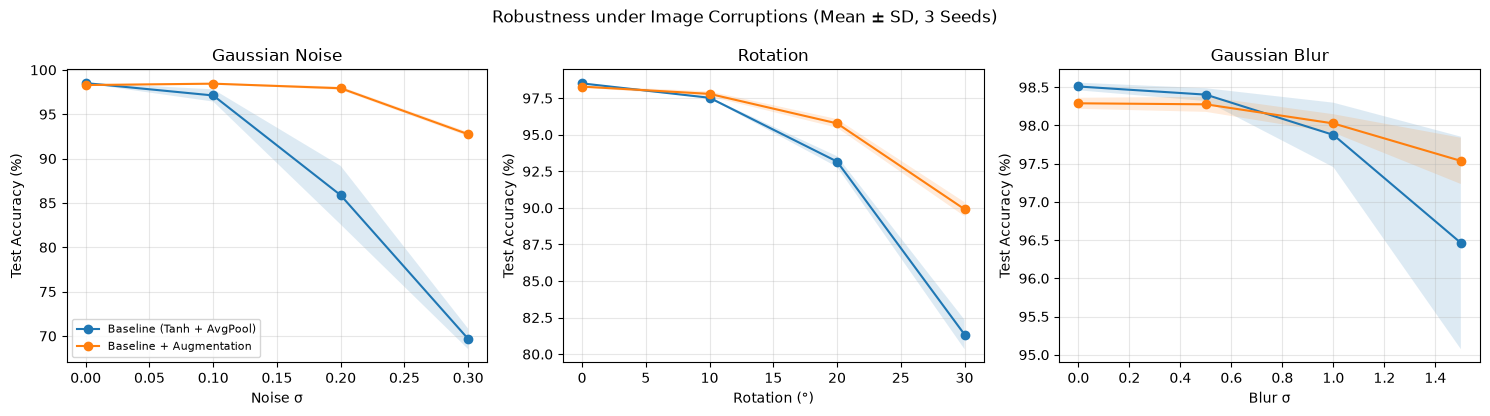

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
corruption_labels = {
    "noise": ("Gaussian Noise", "Noise σ"),
    "rotation": ("Rotation", "Rotation (°)"),
    "blur": ("Gaussian Blur", "Blur σ"),
}

for ax, corruption in zip(axes, corruption_levels, strict=True):
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        data = robustness_summary[
            (robustness_summary["model"] == name) &
            (robustness_summary["corruption"] == corruption)
        ]
        x, y, sd = data["level"], data["accuracy_mean"], data["accuracy_sd"]
        ax.plot(x, y, marker="o", label=MODEL_LABELS[name])
        ax.fill_between(x, y - sd, y + sd, alpha=0.15)

    title, xlabel = corruption_labels[corruption]
    ax.set(title=title, xlabel=xlabel, ylabel="Test Accuracy (%)")
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=8)
plt.suptitle(f"Robustness under Image Corruptions (Mean ± SD, {len(SEEDS)} Seeds)")
plt.tight_layout()
plt.show()

### Nhận xét Robustness Testing

TODO: So sánh accuracy và accuracy degradation của hai mô hình tại mức corruption cao nhất. Nêu rõ augmentation cải thiện loại corruption nào, và có trường hợp nào không cải thiện hoặc giảm performance hay không.

## 6. Inference Latency

Inference latency được đo với batch size 1, sau 20 lần warmup và qua 100 lần đo cho từng mô hình/seed. Khi chạy trên GPU, phép đo đồng bộ GPU trước khi ghi nhận thời gian hoàn tất inference.

Bảng tổng hợp median latency và 95th-percentile latency (P95). Các phép đo không bao gồm đọc dữ liệu từ đĩa, preprocessing hoặc network overhead; kết quả chỉ áp dụng cho môi trường thực thi này.

In [26]:
@torch.inference_mode()
def measure_latency(model, repeats=100, warmup=20):
    model.eval()
    image = test_data[0][0].unsqueeze(0).to(DEVICE)

    for _ in range(warmup):
        model(image)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    durations_ms = []
    for _ in range(repeats):
        started = time.perf_counter()
        model(image)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        durations_ms.append(1_000 * (time.perf_counter() - started))

    return np.median(durations_ms), np.percentile(durations_ms, 95)

In [27]:
latency_rows = []
for seed in SEEDS:
    for name in (*variants, "augmented_tanh_avg"):
        median_ms, p95_ms = measure_latency(models[(name, seed)])
        latency_rows.append({
            "seed": seed, "model": name,
            "median_ms": median_ms, "p95_ms": p95_ms
        })

latency_runs = pd.DataFrame(latency_rows)
latency_summary = latency_runs.groupby("model", sort=False).agg(
    median_mean_ms=("median_ms", "mean"),
    median_sd_ms=("median_ms", "std"),
    p95_mean_ms=("p95_ms", "mean")
)

table = pd.DataFrame({
    "Architecture": latency_summary.index.map(MODEL_LABELS),
    "Median Latency (ms)": [
        f"{m:.3f} ± {s:.3f}"
        for m, s in zip(latency_summary["median_mean_ms"], latency_summary["median_sd_ms"])
    ],
    "P95 Latency (ms)": latency_summary["p95_mean_ms"].map("{:.3f}".format).values
})

display(table.style.hide(axis="index"))

Architecture,Median Latency (ms),P95 Latency (ms)
Baseline (Tanh + AvgPool),0.060 ± 0.000,0.067
ReLU + AvgPool,0.062 ± 0.000,0.069
Tanh + MaxPool,0.062 ± 0.000,0.070
Tanh + AvgPool (no Conv2),0.048 ± 0.000,0.055
Baseline + Augmentation,0.060 ± 0.000,0.067


### Nhận xét Inference Latency

TODO: Điền median latency và P95 của các cấu hình đáng chú ý. Phân tích trade-off với accuracy/parameter count và tránh suy rộng kết quả ra phần cứng khác.

## 7. Cross-Dataset Evaluation: MNIST vs. EMNIST Digits

EMNIST Digits có cùng 10 nhãn chữ số (0–9) với MNIST nhưng gồm các mẫu chữ viết tay từ nguồn dữ liệu khác. Mô hình chỉ được huấn luyện trên MNIST và đánh giá trực tiếp trên tập test EMNIST Digits, không fine-tune.

Ảnh EMNIST được transpose trước khi pad về 32 × 32. Một số ảnh mẫu được hiển thị để kiểm tra preprocessing. Đây là kiểm tra khả năng tổng quát hóa giữa hai bộ dữ liệu chữ viết tay, không đại diện cho tất cả tình huống OCR ngoài thực tế.

Dataset reference: [NIST EMNIST](https://www.nist.gov/itl/products-and-services/emnist-dataset).

EMNIST Digits test: 40,000 ảnh; 10 lớp


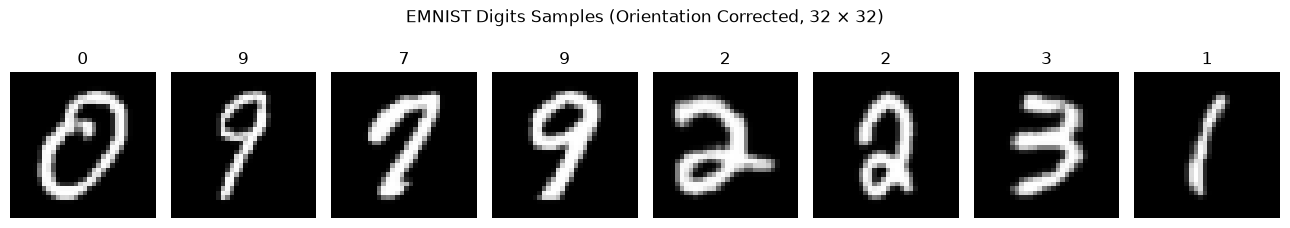

In [28]:
emnist_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.transpose(Image.Transpose.TRANSPOSE)),
    transforms.Pad(2), transforms.ToTensor()
])

emnist_test = datasets.EMNIST(
    "data", split="digits", train=False, download=True, transform=emnist_transform
)
emnist_loader = make_loader(emnist_test)
assert set(emnist_test.targets.unique().tolist()) == set(range(10))
print(f"EMNIST Digits test: {len(emnist_test):,} ảnh; 10 lớp")

fig, axes = plt.subplots(1, 8, figsize=(13, 2.5))
for ax, idx in zip(axes, range(8), strict=True):
    image, label = emnist_test[idx]
    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(label))
    ax.axis("off")

plt.suptitle("EMNIST Digits Samples (Orientation Corrected, 32 × 32)")
plt.tight_layout()
plt.show()

In [29]:
emnist_rows = []
for seed in SEEDS:
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        result = evaluate(models[(name, seed)], emnist_loader)
        mnist_acc = 100 * clean_accuracy[(name, seed)]
        emnist_acc = 100 * result["accuracy"]

        emnist_rows.append({
            "seed": seed, "model": name,
            "mnist_accuracy_pct": mnist_acc,
            "emnist_accuracy_pct": emnist_acc,
            "cross_dataset_drop_pp": mnist_acc - emnist_acc
        })

emnist_runs = pd.DataFrame(emnist_rows)
emnist_summary = emnist_runs.groupby("model", sort=False).agg(
    mnist_mean=("mnist_accuracy_pct", "mean"), mnist_sd=("mnist_accuracy_pct", "std"),
    emnist_mean=("emnist_accuracy_pct", "mean"), emnist_sd=("emnist_accuracy_pct", "std"),
    drop_mean=("cross_dataset_drop_pp", "mean"), drop_sd=("cross_dataset_drop_pp", "std")
)

table = pd.DataFrame(index=emnist_summary.index)
for title, prefix in [
    ("MNIST Accuracy (%)", "mnist"),
    ("EMNIST Accuracy (%)", "emnist"),
    ("Cross-Dataset Drop (pp)", "drop")
]:
    table[title] = [
        f"{m:.2f} ± {s:.2f}"
        for m, s in zip(emnist_summary[f"{prefix}_mean"], emnist_summary[f"{prefix}_sd"])
    ]

display(table.rename(index=MODEL_LABELS).rename_axis("Model").style)

,MNIST Accuracy (%),EMNIST Accuracy (%),Cross-Dataset Drop (pp)
Model,,,
Baseline (Tanh + AvgPool),98.51 ± 0.05,87.43 ± 1.29,11.08 ± 1.27
Baseline + Augmentation,98.29 ± 0.07,89.18 ± 1.63,9.11 ± 1.55


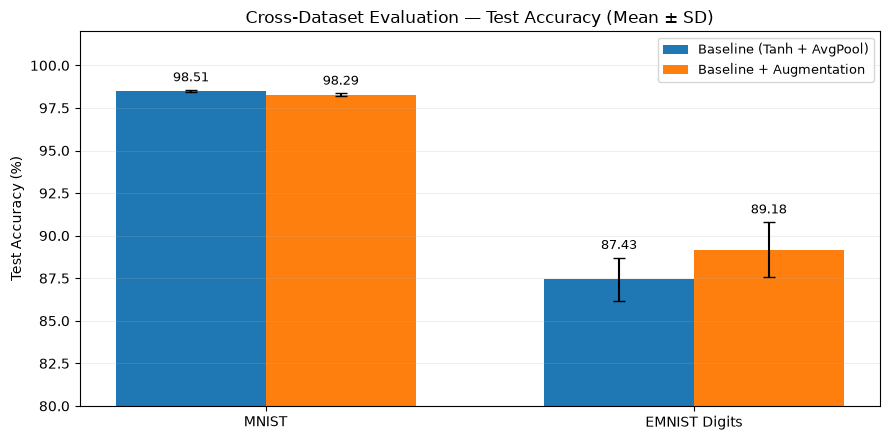

In [30]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x, width = np.arange(2), 0.35

for i, name in enumerate(emnist_summary.index):
    row = emnist_summary.loc[name]
    bars = ax.bar(
        x + (i - 0.5) * width,
        [row["mnist_mean"], row["emnist_mean"]], width,
        yerr=[row["mnist_sd"], row["emnist_sd"]],
        capsize=4, label=MODEL_LABELS[name]
    )
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)

ax.set(
    xticks=x, xticklabels=["MNIST", "EMNIST Digits"],
    ylim=(80, 102), ylabel="Test Accuracy (%)",
    title="Cross-Dataset Evaluation — Test Accuracy (Mean ± SD)"
)
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

### Nhận xét Cross-Dataset Evaluation

TODO: Ghi clean MNIST accuracy, EMNIST Digits accuracy và cross-dataset drop (pp). So sánh baseline với augmented model và liên hệ với Error Analysis ở mục tiếp theo.

## 8. Error Analysis

Overall accuracy không chỉ ra mô hình thường nhầm các cặp chữ số nào. Confusion matrix được chuẩn hóa theo true label để so sánh giữa MNIST và EMNIST Digits; per-class accuracy được tính từ đường chéo của ma trận này.

Các hình minh họa sử dụng seed 42. Đây là case study của một mô hình cụ thể, không thay thế thống kê qua ba seed ở các phần trước.

In [31]:
@torch.inference_mode()
def collect_predictions(model, loader):
    model.eval()
    labels_all, predictions_all = [], []
    for images, labels in loader:
        predictions = model(images.to(DEVICE)).argmax(1).cpu()
        labels_all.append(labels.numpy())
        predictions_all.append(predictions.numpy())
    return np.concatenate(labels_all), np.concatenate(predictions_all)


def confusion_counts(labels, predictions, classes=10):
    counts = np.zeros((classes, classes), dtype=np.int64)
    np.add.at(counts, (labels, predictions), 1)
    return counts


def row_accuracy(counts):
    totals = counts.sum(axis=1)
    return 100 * np.divide(
        np.diag(counts), totals, out=np.zeros(10, dtype=float), where=totals > 0
    )


analysis_seed = SEEDS[0]
error_cases = {}

for dataset_name, loader in (("MNIST", test_loader), ("EMNIST", emnist_loader)):
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        labels, predictions = collect_predictions(models[(name, analysis_seed)], loader)
        error_cases[(dataset_name, name)] = {
            "labels": labels, "predictions": predictions,
            "matrix": confusion_counts(labels, predictions)
        }

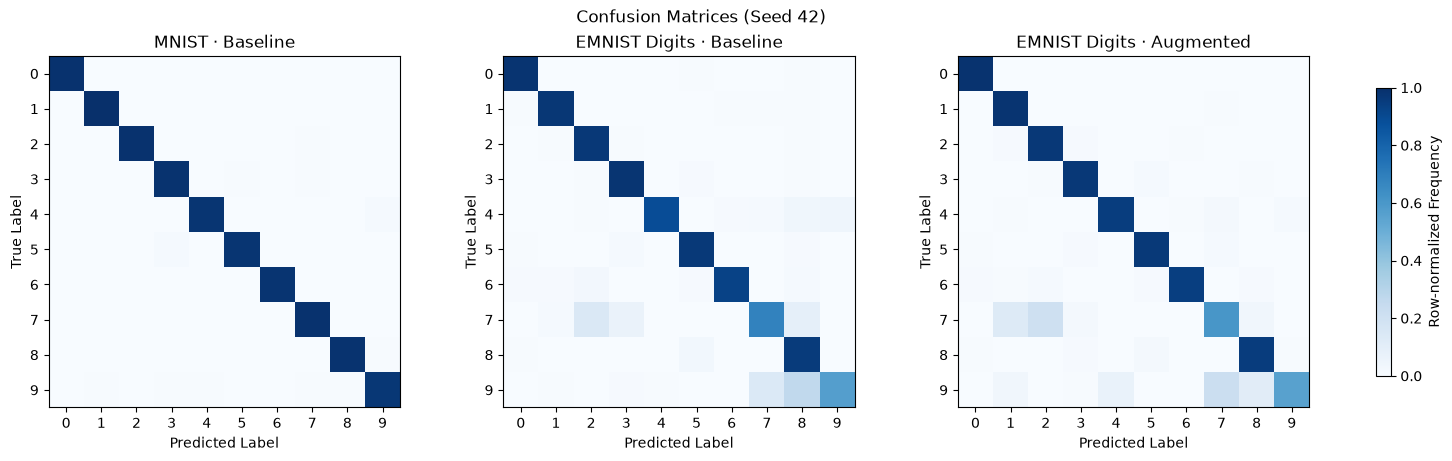

Digit,MNIST Baseline (%),EMNIST Baseline (%),EMNIST Augmented (%)
0,99.180000,98.200000,98.450000
1,99.650000,96.900000,98.200000
2,98.840000,96.720000,96.720000
3,98.710000,97.820000,96.700000
4,97.760000,88.800000,94.580000
5,97.760000,96.150000,96.120000
6,98.430000,92.700000,94.480000
7,98.930000,68.200000,60.250000
8,98.670000,95.430000,94.920000
9,96.930000,56.720000,55.550000


In [32]:
cases_to_plot = [
    ("MNIST", "baseline_tanh_avg", "MNIST · Baseline"),
    ("EMNIST", "baseline_tanh_avg", "EMNIST Digits · Baseline"),
    ("EMNIST", "augmented_tanh_avg", "EMNIST Digits · Augmented"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

for ax, (dataset, name, title) in zip(axes, cases_to_plot, strict=True):
    counts = error_cases[(dataset, name)]["matrix"]
    totals = counts.sum(axis=1, keepdims=True)
    normalized = np.divide(counts, totals, out=np.zeros_like(counts, dtype=float), where=totals > 0)

    im = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    ax.set(title=title, xlabel="Predicted Label", ylabel="True Label")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

fig.colorbar(im, ax=axes, shrink=0.82, label="Row-normalized Frequency")
fig.suptitle("Confusion Matrices (Seed 42)")
plt.show()

per_class = pd.DataFrame({
    "digit": range(10),
    "mnist_baseline_pct": row_accuracy(error_cases[("MNIST", "baseline_tanh_avg")]["matrix"]),
    "emnist_baseline_pct": row_accuracy(error_cases[("EMNIST", "baseline_tanh_avg")]["matrix"]),
    "emnist_augmented_pct": row_accuracy(error_cases[("EMNIST", "augmented_tanh_avg")]["matrix"])
})
display(per_class.rename(columns={"digit": "Digit", "mnist_baseline_pct": "MNIST Baseline (%)", "emnist_baseline_pct": "EMNIST Baseline (%)", "emnist_augmented_pct": "EMNIST Augmented (%)"}).round(2).style.hide(axis="index"))

True Digit,Predicted Digit,Number of Errors
9,8,1058
7,2,584
9,7,557
7,8,347
7,3,262
4,9,176
4,8,144
8,5,121
6,2,107
6,8,62


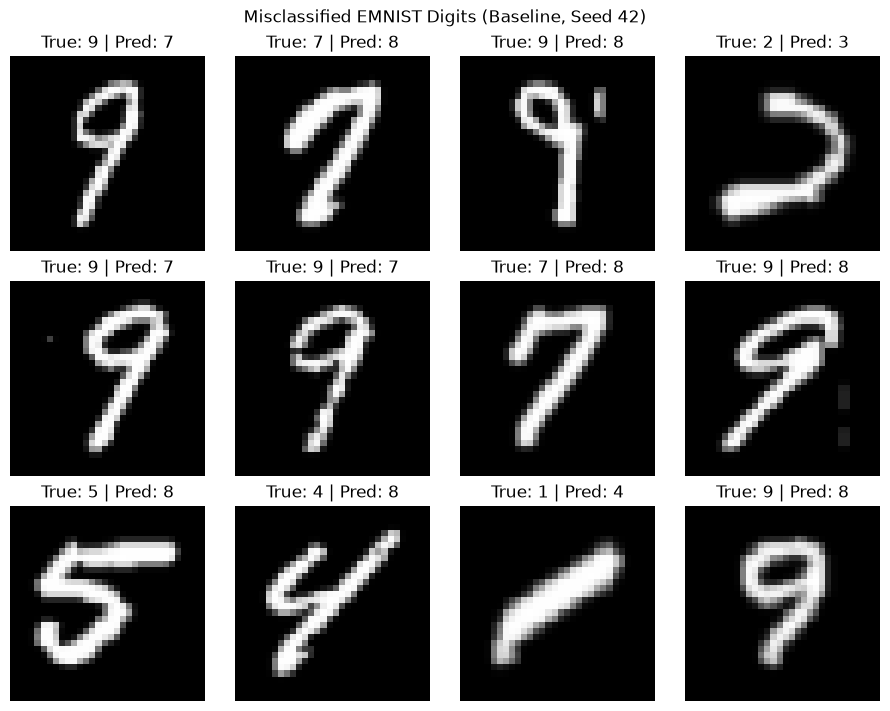

In [33]:
emnist_baseline = error_cases[("EMNIST", "baseline_tanh_avg")]
cm = emnist_baseline["matrix"].copy()
np.fill_diagonal(cm, 0)

confusion_pairs = [
    (actual, predicted, int(cm[actual, predicted]))
    for actual in range(10) for predicted in range(10)
    if cm[actual, predicted] > 0
]
confusion_pairs.sort(key=lambda x: x[2], reverse=True)
display(pd.DataFrame(
    confusion_pairs[:10], columns=["True Digit", "Predicted Digit", "Number of Errors"]
).style.hide(axis="index"))

wrong_indices = np.flatnonzero(
    emnist_baseline["labels"] != emnist_baseline["predictions"]
)[:12]

fig, axes = plt.subplots(3, 4, figsize=(9, 7), constrained_layout=True)
for ax, idx in zip(axes.flat, wrong_indices):
    image, label = emnist_test[int(idx)]
    prediction = int(emnist_baseline["predictions"][idx])
    ax.imshow(image.squeeze().numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True: {label} | Pred: {prediction}")
    ax.axis("off")

for ax in list(axes.flat)[len(wrong_indices):]:
    ax.axis("off")

plt.suptitle("Misclassified EMNIST Digits (Baseline, Seed 42)")
plt.show()

Confusion matrices được chuẩn hóa theo true label để so sánh tỷ lệ nhầm lẫn dù MNIST và EMNIST có quy mô test khác nhau. Bảng các cặp nhầm lẫn thể hiện số lỗi tuyệt đối trên EMNIST Digits của baseline với seed 42.

Misclassified samples chỉ hỗ trợ diễn giải định tính. Chưa thể kết luận nguyên nhân từ vài ảnh minh họa, đặc biệt khi khác biệt preprocessing và nét viết có thể cùng ảnh hưởng đến kết quả.

### Nhận xét Error Analysis

TODO: Từ `per_class` và bảng `confusion_pairs`, xác định các chữ số/cặp chữ số dễ nhầm nhất trên EMNIST Digits. Kiểm tra xem Data Augmentation có giúp cải thiện những lớp đó không; đối chiếu với misclassified samples.

## 9. Adversarial Robustness: FGSM

Khác với Gaussian noise trong Robustness Testing, Fast Gradient Sign Method (FGSM) sử dụng gradient của classification loss theo input image để tạo perturbation làm giảm khả năng dự đoán. Đây là white-box attack: mỗi mô hình bị tấn công dựa trên gradient của chính mô hình đó.

Thí nghiệm dùng 2.048 ảnh MNIST test cố định với ε ∈ {0, 0.05, 0.10, 0.20} trên thang pixel [0, 1]. Chỉ vùng 28 × 28 của ảnh gốc được perturb; padding 2 pixels giữ nguyên. So sánh baseline và augmented model qua ba seed, không adversarially train.

Ngoài adversarial accuracy, attack success rate được tính trên các mẫu ban đầu dự đoán đúng. Hai mô hình có gradient khác nhau nên không nhất thiết nhận cùng một perturbation.

In [34]:
FGSM_EPSILONS = (0.0, 0.05, 0.10, 0.20)
FGSM_SUBSET_SIZE = 2048
fgsm_indices = np.random.default_rng(2026).choice(
    len(test_data), size=FGSM_SUBSET_SIZE, replace=False
)
fgsm_loader = make_loader(Subset(test_data, fgsm_indices.tolist()))

def fgsm_attack(model, images, labels, epsilon):
    if epsilon == 0:
        return images.detach()

    with torch.enable_grad():
        x = images.detach().clone().requires_grad_(True)
        loss = torch.nn.functional.cross_entropy(model(x), labels)
        gradient = torch.autograd.grad(loss, x)[0]
        mask = torch.zeros_like(x)
        mask[:, :, 2:-2, 2:-2] = 1
        return (x.detach() + epsilon * gradient.sign() * mask).clamp(0, 1)


def evaluate_fgsm(model, loader, epsilon):
    model.eval()
    total = clean_correct_total = attacked_correct_total = retained_correct = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        with torch.no_grad():
            clean_ok = model(images).argmax(1).eq(labels)

        attacked_images = fgsm_attack(model, images, labels, epsilon)
        with torch.no_grad():
            attacked_ok = model(attacked_images).argmax(1).eq(labels)

        total += labels.numel()
        clean_correct_total += int(clean_ok.sum().item())
        attacked_correct_total += int(attacked_ok.sum().item())
        retained_correct += int((clean_ok & attacked_ok).sum().item())

    success_rate = (
        100 * (clean_correct_total - retained_correct) / clean_correct_total
        if clean_correct_total else float("nan")
    )
    return 100 * attacked_correct_total / total, success_rate

Model,FGSM ε,Adversarial Accuracy (%),Attack Success Rate (%)
Baseline (Tanh + AvgPool),0.000000,98.83 ± 0.13,0.00 ± 0.00
Baseline (Tanh + AvgPool),0.050000,76.43 ± 3.84,22.66 ± 3.99
Baseline (Tanh + AvgPool),0.100000,37.47 ± 2.21,62.09 ± 2.28
Baseline (Tanh + AvgPool),0.200000,9.29 ± 1.22,90.60 ± 1.24
Baseline + Augmentation,0.000000,98.58 ± 0.25,0.00 ± 0.00
Baseline + Augmentation,0.050000,89.88 ± 0.33,8.83 ± 0.48
Baseline + Augmentation,0.100000,65.54 ± 2.25,33.52 ± 2.16
Baseline + Augmentation,0.200000,21.06 ± 2.31,78.64 ± 2.32


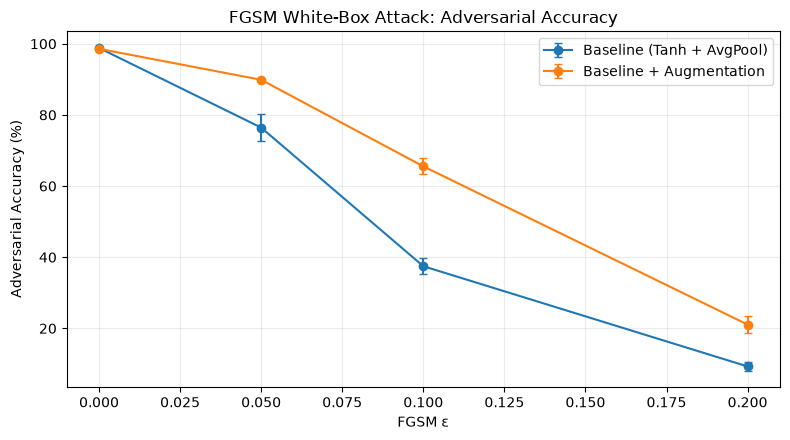

In [35]:
fgsm_rows = []
for seed in SEEDS:
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        model = models[(name, seed)]
        for epsilon in FGSM_EPSILONS:
            adv_acc, success_rate = evaluate_fgsm(model, fgsm_loader, epsilon)
            fgsm_rows.append({
                "seed": seed, "model": name, "epsilon": epsilon,
                "adversarial_accuracy_pct": adv_acc,
                "attack_success_rate_pct": success_rate
            })

fgsm_runs = pd.DataFrame(fgsm_rows)
fgsm_summary = fgsm_runs.groupby(["model", "epsilon"], sort=False).agg(
    accuracy_mean=("adversarial_accuracy_pct", "mean"),
    accuracy_sd=("adversarial_accuracy_pct", "std"),
    success_mean=("attack_success_rate_pct", "mean"),
    success_sd=("attack_success_rate_pct", "std")
).reset_index()

table = fgsm_summary[["model", "epsilon"]].copy()
for title, prefix in [("Adversarial Accuracy (%)", "accuracy"), ("Attack Success Rate (%)", "success")]:
    table[title] = [
        f"{m:.2f} ± {s:.2f}"
        for m, s in zip(fgsm_summary[f"{prefix}_mean"], fgsm_summary[f"{prefix}_sd"])
    ]

display(table.rename(columns={"model": "Model", "epsilon": "FGSM ε"})
        .assign(Model=lambda df: df["Model"].map(MODEL_LABELS))
        .style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
    data = fgsm_summary[fgsm_summary["model"] == name]
    ax.errorbar(data["epsilon"], data["accuracy_mean"], yerr=data["accuracy_sd"],
                marker="o", capsize=3, label=MODEL_LABELS[name])

ax.set(xlabel="FGSM ε", ylabel="Adversarial Accuracy (%)",
       title="FGSM White-Box Attack: Adversarial Accuracy")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

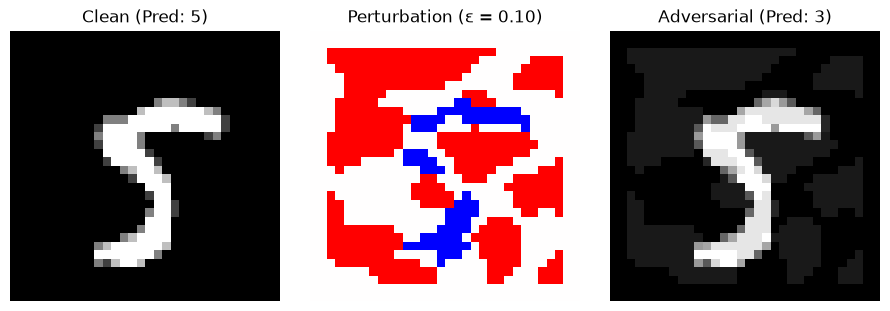

True label: 5


In [36]:
# Illustrate one successful white-box attack when possible (baseline, seed 42).
example_model = models[("baseline_tanh_avg", analysis_seed)]
example_images, example_labels = next(iter(fgsm_loader))
example_images, example_labels = example_images.to(DEVICE), example_labels.to(DEVICE)

example_adv = fgsm_attack(example_model, example_images, example_labels, 0.10)
with torch.no_grad():
    before = example_model(example_images).argmax(1)
    after = example_model(example_adv).argmax(1)

candidates = torch.nonzero(before.eq(example_labels) & after.ne(example_labels), as_tuple=True)[0]
chosen = int(candidates[0].item()) if len(candidates) else 0

clean_image = example_images[chosen, 0].detach().cpu().numpy()
adversarial_image = example_adv[chosen, 0].detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(9, 3), constrained_layout=True)
titles = [
    f"Clean (Pred: {int(before[chosen])})",
    "Perturbation (ε = 0.10)",
    f"Adversarial (Pred: {int(after[chosen])})",
]
images = [
    (clean_image, "gray", 0, 1),
    (adversarial_image - clean_image, "bwr", -0.1, 0.1),
    (adversarial_image, "gray", 0, 1),
]

for ax, title, (img, cmap, vmin, vmax) in zip(axes, titles, images, strict=True):
    ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")

plt.show()
print(f"True label: {int(example_labels[chosen])}")

FGSM và image corruption đánh giá hai loại perturbation khác nhau. Adversarial accuracy giảm theo ε phản ánh độ nhạy của mô hình trước white-box FGSM trong thiết lập này, không đo trực tiếp robustness trước nhiễu ngẫu nhiên hoặc ảnh tự nhiên.

Data Augmentation thông thường không tương đương adversarial training. Nếu mô hình augmented hoạt động tốt hơn hay kém hơn dưới FGSM, nhận xét cần giới hạn trong loại attack và phạm vi ε đã kiểm tra.

### Nhận xét FGSM

TODO: Điền adversarial accuracy và attack success rate tại ε = 0.05, 0.10, 0.20. So sánh baseline và augmented model, nhưng không quy kết kết quả cho các adversarial attack khác.

## 10. Discussion

Các kết quả cần được đọc cùng nhau: Ablation Study trả lời câu hỏi về lựa chọn kiến trúc; Convergence Analysis theo dõi training dynamics; Robustness Testing và FGSM đánh giá hai kiểu perturbation khác nhau; Cross-Dataset Evaluation và Error Analysis xem xét khả năng tổng quát hóa cũng như cấu trúc lỗi.

Phần tổng kết bên dưới để trống các kết luận định lượng cho đến khi thực hiện lại toàn bộ thí nghiệm với 10 epochs và ba seed.

### Kết quả chính

TODO: Hoàn thiện đoạn tổng kết sau khi chạy notebook. Có thể dùng các gợi ý sau:

- Ablation Study: biến thể có test accuracy cao nhất là `[model]` với `[mean ± SD]%`; chênh lệch so với baseline là `[Δ ± SD]` pp. Nêu trade-off giữa accuracy, parameters và training time.
- Convergence Analysis: validation accuracy ở epoch 3 là `[x]%` và epoch 10 là `[y]%` (seed 42). Nhận xét mức cải thiện, khoảng cách train–validation và dấu hiệu overfitting nếu có.
- Robustness Testing: tại mức Gaussian noise σ = 0.3, baseline đạt `[x]%` còn augmented đạt `[y]%`; xem thêm rotation và blur trước khi kết luận.
- Cross-Dataset Evaluation: accuracy trên EMNIST Digits của baseline/augmented là `[x]%` / `[y]%`; so sánh với MNIST test và Error Analysis.
- FGSM: khi ε = 0.10, adversarial accuracy là `[x]%` / `[y]%`. Phân biệt kết quả này với corruption robustness.

TODO: Viết kết luận ngắn về điều kiện mà từng phương án đem lại lợi ích và những giới hạn khiến kết luận chưa thể tổng quát hóa.

## 11. Limitations

- Các kết quả được tổng hợp trên ba seed và cùng một train/validation split; chưa khảo sát biến thiên do thay đổi dữ liệu chia tập.
- Mọi cấu hình được huấn luyện trong 10 epochs. Đây là cùng training budget, nhưng chưa đảm bảo cùng thời điểm hội tụ hoặc cùng mức độ tối ưu của từng kiến trúc.
- Bỏ Conv2 đồng thời làm thay đổi kích thước classifier và model capacity; chưa thể quy toàn bộ thay đổi performance cho riêng tầng Conv2.
- Corruption robustness và FGSM white-box không đại diện cho toàn bộ các tình huống trong triển khai thực tế hoặc các attack mạnh hơn.
- EMNIST Digits vẫn là dữ liệu chữ số viết tay; khả năng tổng quát hóa sang ảnh chụp/OCR thực tế cần được kiểm tra riêng.
- Inference latency phụ thuộc hardware, phiên bản thư viện và thiết kế benchmark.

TODO: Bổ sung giới hạn cụ thể rút ra từ kết quả sau khi chạy thí nghiệm.

## 12. References

1. LeCun et al., [Gradient-Based Learning Applied to Document Recognition (LeNet-5)](http://yann.lecun.com/exdb/lenet/).
2. [Torchvision MNIST](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html) và [Torchvision EMNIST](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.EMNIST.html).
3. Cohen et al., [EMNIST: Extending MNIST to handwritten letters](https://arxiv.org/abs/1702.05373).
4. Goodfellow et al., [Explaining and Harnessing Adversarial Examples](https://arxiv.org/abs/1412.6572).
5. [PyTorch Reproducibility](https://pytorch.org/docs/stable/notes/randomness.html).